In [66]:
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging

logging.getLogger().setLevel(logging.ERROR)
basepath =  r"W:\data\PPP\PPP8\day8"
basename=os.path.basename(basepath)# Define the new folder path
#create working folder
new_folder_path = os.path.join(basepath, "complex_system")
brain_region="CA1"
animal="mouse"   #or Mouse
cell_type='all'
path_parts = basepath.split("\\")  # Split the path using backslash
animal_name = path_parts[-2]  # Second-to-last part is the animal name
day = path_parts[-1]  # Last part is the day
save_dir = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\complex_system\manifold"
if not os.path.exists(save_dir):
    os.makedirs(save_dir)
# Create the folder if it doesn't exist
if not os.path.exists(new_folder_path):
    os.makedirs(new_folder_path)
    print(f"Folder created: {new_folder_path}")
else:
    print(f"Folder already exists: {new_folder_path}")
# load in spike data from hpc pyramidal cells
st, cm = loading.load_spikes(
    basepath, brainRegion=brain_region                          # putativeCellType="Pyr"
)
# load theta epochs
state_dict = loading.load_SleepState_states(basepath)
nrem_epochs = nel.EpochArray(
    state_dict["NREMstate"],
)
awake_epochs = nel.EpochArray(
    state_dict["WAKEstate"],
)
theta_epochs = nel.EpochArray(
    state_dict["THETA"],
)
rem_epochs=nel.EpochArray(state_dict["REMstate"],)
# Load ripple events
ripple_events = loading.load_ripples_events(basepath=basepath)
ripple_epochs = nel.EpochArray(np.array([ripple_events.start, ripple_events.stop]).T)
ripple_peaks=ripple_events.peaks
    # Load barrage events
ripple_epochs=nrem_epochs&ripple_epochs
    # Try default loader
epoch_df = loading.load_epoch(basepath)
sleep_epochs = nel.EpochArray(np.array([epoch_df.startTime, epoch_df.stopTime]).T)
E_spikes = st.time[(cm.putativeCellType == 'Pyramidal Cell')]
I_spikes= st.time[(cm.putativeCellType.str.contains("Interneuron"))]
spike_times=st.time
n_cell=len(spike_times)
print(f"number of cells: {n_cell}")
n_pyr=len(E_spikes)
print(f"number of pyramidal cells: {n_pyr}")
print(f"nrem duration: {nrem_epochs.durations.sum():.2f} seconds")
print(f"rrem duration: {rem_epochs.durations.sum():.2f} seconds")
print(f"theta duration: {theta_epochs.durations.sum():.2f} seconds")

Folder already exists: W:\data\PPP\PPP8\day8\complex_system
number of cells: 125
number of pyramidal cells: 108
nrem duration: 12981.00 seconds
rrem duration: 179.00 seconds
theta duration: 1754.00 seconds


In [67]:
import os, re, numpy as np, pandas as pd
import glob  # <-- add this
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False,
            simplify_cells=True
        )
    except TypeError:
        return loadmat(
            mat_path,
            squeeze_me=True,
            struct_as_record=False
        )
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)
def _to_1d_array(x):
    """
    Robustly coerce MATLAB-loaded field to a 1D numpy array.
    - Scalars -> 1-length array
    - Lists/tuples/ndarrays -> flattened 1D
    - None / missing -> empty array
    """
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)  # start as object to avoid surprises
    if arr.ndim == 0:
        # scalar or unsized object
        return np.atleast_1d(arr).astype(float, copy=False)
    # flatten and try float cast (ignore non-numeric gracefully)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        # fallback: best-effort, convert elementwise
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    # MATLAB char arrays sometimes come in as numpy arrays
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        # arrays or weird containers -> join characters
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        # e.g., array of characters
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def load_d2_timeline_complete(basepath, region):
    """Complete version that loads ALL sleep-state data, including d2_err."""
    region = region.upper()
    search_dir = os.path.join(basepath, "complex_system")
    pats = [f"*_{region}_D2_time_resolved_rippleablate.mat", f"*_{region}_D2_time_rippleablate.mat"]
    #pats = [f"*_{region}_D2_time_resolved_error_bar.mat", f"*_{region}_D2_time_resolved_error_bar.mat"]
    files = []
    for pat in pats:
        files.extend(glob.glob(os.path.join(search_dir, pat)))
    if not files:
        raise FileNotFoundError(f"No *_{region}_D2_time*.mat under {search_dir}")

    mat_path = max(files, key=os.path.getmtime)
    print(f"Loading: {os.path.basename(mat_path)}")

    mat = _load_mat_any(mat_path)
    results = mat['results']
    params = mat.get('params', {})

    # Make results iterable no matter if it's a list, ndarray, or dict
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    print(f"📊 Found {len(iter_results)} result items (sleep states)")
    print(f"📊 Parameters: {params}")

    # Try to infer animal/day from filename if available
    fname = os.path.basename(mat_path)
    animal_name = None
    day = None
    m_day = re.search(r'day(\d+)', fname, flags=re.I)
    if m_day:
        day = int(m_day.group(1))
    m_animal = re.match(r'([^_]+)_day\d+_', fname)
    if m_animal:
        animal_name = m_animal.group(1)

    all_centers, all_d2, all_d2err, all_states = [], [], [], []
    n_states_with_err = 0

    for i, result_item in enumerate(iter_results):
        # Access as dict-like regardless of MATLAB struct quirks
        state = _to_state_str(result_item.get('state', 'UNKNOWN')) if hasattr(result_item, 'get') else \
                _to_state_str(result_item['state']) if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) else 'UNKNOWN'

        centers_raw = result_item.get('center', []) if hasattr(result_item, 'get') else \
                      (result_item['center'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'center' in result_item else [])
        d2_raw = result_item.get('d2', []) if hasattr(result_item, 'get') else \
                 (result_item['d2'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2' in result_item else [])
        d2err_raw = result_item.get('d2_err', []) if hasattr(result_item, 'get') else \
                    (result_item['d2_err'] if (isinstance(result_item, dict) or hasattr(result_item, '__getitem__')) and 'd2_err' in result_item else [])

        centers  = _to_1d_array(centers_raw)
        d2_vals  = _to_1d_array(d2_raw)
        d2_err   = _to_1d_array(d2err_raw)

        # Presence flag (some states may not have d2_err)
        has_err = d2_err.size > 0 and np.any(np.isfinite(d2_err))
        n_states_with_err += int(has_err)

        # Harmonize lengths: truncate all to the common min
        sizes = [centers.size, d2_vals.size] + ([d2_err.size] if has_err else [])
        n_pts = min(sizes) if min(sizes) > 0 else 0
        print(f"   State {i}: {state} - requested points={centers.size}, actual used={n_pts}")

        if n_pts == 0:
            print("     ⚠️ Empty state - no data points")
            continue

        centers = centers[:n_pts]
        d2_vals = d2_vals[:n_pts]
        d2_err  = (d2_err[:n_pts] if has_err else np.full(n_pts, np.nan, dtype=float))

        # Ranges
        try:
            print(f"     Time range: {float(np.nanmin(centers))} to {float(np.nanmax(centers))}")
        except ValueError:
            print("     Time range: (all NaN)")

        try:
            print(f"     D2 range: {float(np.nanmin(d2_vals)):.4f} to {float(np.nanmax(d2_vals)):.4f}")
        except ValueError:
            print("     D2 range: (all NaN)")

        if np.any(np.isfinite(d2_err)):
            try:
                dmin, dmax = float(np.nanmin(d2_err)), float(np.nanmax(d2_err))
                print(f"     D2_ERR range: {dmin:.4f} to {dmax:.4f}")
            except ValueError:
                print("     D2_ERR range: (all NaN)")
        else:
            print("     D2_ERR: missing → filled with NaN")

        all_centers.append(centers)
        all_d2.append(d2_vals)
        all_d2err.append(d2_err)
        all_states.append(np.array([state]*n_pts, dtype=object))

    if len(all_centers) == 0:
        raise ValueError("No data found in any sleep state - all states are empty")

    # Concatenate
    all_centers = np.concatenate(all_centers)
    all_d2      = np.concatenate(all_d2)
    all_d2err   = np.concatenate(all_d2err)
    all_states  = np.concatenate(all_states)

    # DataFrame (include d2_err)
    df = pd.DataFrame({
        'center_s': all_centers.astype(float, copy=False),
        'd2':       all_d2.astype(float, copy=False),
        'd2_err':   all_d2err.astype(float, copy=False),
        'state':    all_states.astype(str)
    }).sort_values('center_s').reset_index(drop=True)

    print(f"\n✅ Complete timeline created:")
    print(f"📊 Total data points: {len(df)}")
    print(f"📊 Time range: {df['center_s'].min()} to {df['center_s'].max()}")
    print(f"📊 Duration: {(df['center_s'].max() - df['center_s'].min()):.1f} seconds")
    print(f"📊 State distribution:")
    print(df['state'].value_counts())

    # Empty-state tracker
    empty_states = []
    for ri in iter_results:
        st = _to_state_str(ri.get('state','UNKNOWN')) if hasattr(ri,'get') else \
             _to_state_str(ri['state']) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'state' in ri else 'UNKNOWN'
        csz = np.size(np.atleast_1d(ri.get('center', []))) if hasattr(ri,'get') else \
              np.size(np.atleast_1d(ri['center'])) if (isinstance(ri,dict) or hasattr(ri,'__getitem__')) and 'center' in ri else 0
        if csz == 0:
            empty_states.append(st)

    meta = {
        "animal_name": animal_name,
        "day": day,
        "region": region,
        "path": mat_path,
        "params": params,
        "columns": list(df.columns),
        "shape": df.shape,
        "n_states": len(iter_results),
        "states_with_d2_err": n_states_with_err,
        "empty_states": empty_states
    }

    return df, meta



# Test the complete loading function
try:
    ca1_complete_df, ca1_complete_meta = load_d2_timeline_complete(basepath, "CA1")
    
    # pfc_complete_df, pfc_complete_meta = load_d2_timeline_complete(basepath, "PFC")

    
except Exception as e:
    print(f"❌ Failed: {e}")
    import traceback
    traceback.print_exc()

print("\n" + "="*60)

Loading: day8_CA1_D2_time_resolved_rippleablate.mat
📊 Found 3 result items (sleep states)
📊 Parameters: {'window_size': 30, 'step_size': 2, 'guard_sec': 5, 'deltaT': 0.04, 'order': 20, 'quant': 0.1, 'brain_region': 'CA1', 'n_cells': 125, 'total_spikes': 9525080}
   State 0: NREM - requested points=5124, actual used=5124
     Time range: 367.0 to 26220.0
     D2 range: 0.0244 to 0.3043
     D2_ERR range: 0.9816 to 0.9959
   State 1: REM - requested points=47, actual used=47
     Time range: 24045.0 to 25855.0
     D2 range: 0.0444 to 0.0944
     D2_ERR range: 0.9803 to 0.9873
   State 2: WAKE - requested points=5140, actual used=5140
     Time range: 21.0 to 25297.0
     D2 range: 0.0152 to 0.2642
     D2_ERR range: 0.9820 to 0.9963

✅ Complete timeline created:
📊 Total data points: 10311
📊 Time range: 21.0 to 26220.0
📊 Duration: 26199.0 seconds
📊 State distribution:
state
WAKE    5140
NREM    5124
REM       47
Name: count, dtype: int64



Annotate prepost

In [68]:
import numpy as np
import pandas as pd
from typing import Optional

def annotate_d2_with_sleep_and_ripple_rate(
    ca1_complete_df: pd.DataFrame,
    epoch_df: pd.DataFrame,
    ripple_epochs_data: np.ndarray,
    window_len: float =30,   # seconds
) -> pd.DataFrame:
    """
    - Adds 'sleep_epoch' to ca1_complete_df: {'presleep','midsleep','postsleep', np.nan}
    - Adds 'ripple_rate_30s' to ca1_complete_df: events/sec within +/- window_len/2 around center_s.
    
    Assumptions:
      * epoch_df has columns: ['name','startTime','stopTime','environment']
      * Only epochs with environment=='sleep' are used for labeling.
      * Ripple events provided as Nx2 array [start, end] in seconds.
        If you only have starts, pass Nx2 with end=start (or see comment below).
    """
    df = ca1_complete_df.copy()

    # -------- 1) Build sleep interval table with labels
    sleep_epochs = epoch_df.copy()
    sleep_epochs = sleep_epochs[sleep_epochs['environment'].astype(str).str.lower()=='sleep'].copy()

    # Normalize names to lower and assign coarse label
    def _label_from_name(n: str) -> Optional[str]:
        s = str(n).lower()
        if 'presleep' in s or 'pre_sleep' in s or 'pre' in s and 'sleep' in s:
            return 'presleep'
        if 'midsleep' in s or 'mid_sleep' in s:
            return 'midsleep'
        if 'postsleep' in s or 'post_sleep' in s or ('post' in s and 'sleep' in s):
            return 'postsleep'
        return None

    sleep_epochs['sleep_epoch'] = sleep_epochs['name'].map(_label_from_name)
    sleep_epochs = sleep_epochs.dropna(subset=['sleep_epoch'])
    # Keep only necessary columns and ensure numeric
    sleep_epochs = sleep_epochs[['startTime','stopTime','sleep_epoch']].astype({'startTime':float,'stopTime':float})

    # -------- Map each center_s to an interval label
    # We'll do this by merging after expanding intervals to non-overlapping rows per center
    centers = df[['center_s']].astype(float).copy()
    centers['row_id___'] = np.arange(len(centers))

    # For efficient interval lookup, sort and then use merge_asof on both boundaries.
    starts = sleep_epochs[['startTime','sleep_epoch']].rename(columns={'startTime':'bound'})
    starts['flag'] = 1
    stops  = sleep_epochs[['stopTime','sleep_epoch']].rename(columns={'stopTime':'bound'})
    stops['flag'] = -1
    bounds = pd.concat([starts, stops], ignore_index=True).sort_values('bound')

    # Sweep-line to know which interval each center falls into
    centers_sorted = centers.sort_values('center_s')
    idx_b = np.searchsorted(bounds['bound'].to_numpy(), centers_sorted['center_s'].to_numpy(), side='right') - 1
    # cumulative sum per label is tricky; simpler: vectorized membership by intervals
    # Use pandas.IntervalIndex for clarity:
    iv = pd.IntervalIndex.from_arrays(sleep_epochs['startTime'].to_numpy(),
                                      sleep_epochs['stopTime'].to_numpy(),
                                      closed='both')
    # get label for each center via interval containment
    membership_codes = iv.get_indexer(centers_sorted['center_s'].to_numpy())
    labels = pd.Series(np.where(membership_codes>=0,
                                sleep_epochs['sleep_epoch'].to_numpy()[membership_codes],
                                np.nan),
                       index=centers_sorted.index)
    centers_sorted['sleep_epoch'] = labels
    # restore original order
    centers = centers_sorted.sort_values('row_id___').drop(columns=['row_id___'])

    df['sleep_epoch'] = centers['sleep_epoch'].values

    # -------- 2) Ripple rate in ±window_len/2 around each center_s
    half = window_len / 2.0
    # ripple_epochs_data expected shape (N,2): start,end.
    rip = np.asarray(ripple_epochs_data, dtype=float)
    if rip.ndim == 1:
        # If only starts are provided, treat end=start (instantaneous)
        rip = np.column_stack([rip, rip])
    elif rip.shape[1] != 2:
        raise ValueError("ripple_epochs_data must be (N,2) [start,end] in seconds.")

    r_start = rip[:,0]
    r_end   = rip[:,1]

    centers_arr = df['center_s'].to_numpy(dtype=float)
    win_starts = centers_arr - half
    win_ends   = centers_arr + half

    # Count overlap: (r_start < win_end) & (r_end > win_start)
    # Vectorized via broadcasting in manageable chunks to avoid huge memory use
    counts = np.zeros(len(centers_arr), dtype=int)
    chunk = 5000  # adjust if needed
    for i0 in range(0, len(centers_arr), chunk):
        i1 = i0 + chunk
        ws = win_starts[i0:i1][:, None]
        we = win_ends[i0:i1][:, None]
        overlap = (r_start[None, :] < we) & (r_end[None, :] > ws)
        counts[i0:i1] = overlap.sum(axis=1)

    df['ripple_rate_30s'] = counts / window_len  # events per second
    # If you prefer events per minute, multiply by 60.

    return df

# ---------------- Example usage ----------------
# ca1_complete_df = ...  # has columns ['center_s','d2','state']
# epoch_df = ...         # has ['name','startTime','stopTime','environment']
# ripple_epochs_data = ...  # Nx2 array of [start,end] in seconds

ca1_complete_df = annotate_d2_with_sleep_and_ripple_rate(ca1_complete_df, epoch_df, ripple_epochs.data)
ca1_complete_df.head()

,center_s,d2,d2_err,state,sleep_epoch,ripple_rate_30s
0,21.0,0.104129,0.992444,WAKE,presleep,0.0
1,23.0,0.104855,0.992413,WAKE,presleep,0.0
2,25.0,0.108535,0.992487,WAKE,presleep,0.0
3,27.0,0.116427,0.993285,WAKE,presleep,0.0
4,29.0,0.121024,0.993088,WAKE,presleep,0.0


ISI entropy ablate spikes from ripples

In [69]:
import numpy as np
import pandas as pd
from typing import Iterable

# =========================
# Utilities
# =========================
def _flatten_spikes(spike_times):
    """Pool spike times across inputs and return sorted unique float seconds."""
    if isinstance(spike_times, dict):
        parts = [np.asarray(v, float).ravel() for v in spike_times.values()]
        x = np.concatenate([p[np.isfinite(p)] for p in parts]) if parts else np.array([], float)
    else:
        arr = np.asarray(spike_times, dtype=object)
        if arr.dtype == object:
            parts = []
            for it in arr:
                if it is None:
                    continue
                v = np.asarray(it, float).ravel()
                v = v[np.isfinite(v)]
                if v.size:
                    parts.append(v)
            if parts:
                x = np.concatenate(parts)
            else:
                try:
                    x = np.asarray(spike_times, float).ravel()
                except (TypeError, ValueError):
                    x = np.array([], float)
        else:
            x = arr.astype(float).ravel()
    x = x[np.isfinite(x)]
    return np.sort(np.unique(x))

def _coerce_epochs(ep):
    """Coerce many epoch formats to a sorted list[(start, stop)]. Accepts ep, or ep.data with ≥2 columns."""
    if hasattr(ep, "data"):
        vals = getattr(ep, "data")
        try:
            if isinstance(vals, pd.DataFrame) and vals.shape[1] >= 2:
                a = vals.iloc[:, 0].astype(float).to_numpy()
                b = vals.iloc[:, 1].astype(float).to_numpy()
                out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
                out.sort(key=lambda t: t[0]); return out
            vals = np.asarray(vals)
            if vals.ndim == 2 and vals.shape[1] >= 2:
                a = vals[:, 0].astype(float); b = vals[:, 1].astype(float)
                out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
                out.sort(key=lambda t: t[0]); return out
        except Exception:
            pass

    if isinstance(ep, pd.DataFrame):
        if {'start','stop'}.issubset(ep.columns):
            a = ep['start'].astype(float).to_numpy()
            b = ep['stop'].astype(float).to_numpy()
        elif {'startTime','stopTime'}.issubset(ep.columns):
            a = ep['startTime'].astype(float).to_numpy()
            b = ep['stopTime'].astype(float).to_numpy()
        else:
            a = ep.iloc[:,0].astype(float).to_numpy()
            b = ep.iloc[:,1].astype(float).to_numpy()
        out = [(s, e) for s, e in zip(a, b) if np.isfinite(s) and np.isfinite(e) and e > s]
        out.sort(key=lambda t: t[0]); return out

    if isinstance(ep, Iterable):
        out = []
        for item in ep:
            try:
                s, e = item
                s, e = float(s), float(e)
                if np.isfinite(s) and np.isfinite(e) and e > s:
                    out.append((s, e))
            except Exception:
                pass
        out.sort(key=lambda t: t[0]); return out

    return []

def _centers_within_long_epochs(centers_s, epochs_data, min_dur=60.0):
    """
    centers_s: 1D array of center times (sec)
    epochs_data: (N,2) array-like [[start,end], ...] in seconds
    """
    ep = np.asarray(epochs_data, dtype=float)
    if ep.size == 0:
        return np.zeros(len(centers_s), dtype=bool)

    dur = ep[:, 1] - ep[:, 0]
    ep = ep[dur >= float(min_dur)]
    if ep.size == 0:
        return np.zeros(len(centers_s), dtype=bool)

    order = np.argsort(ep[:, 0])
    ep = ep[order]
    starts, ends = ep[:, 0], ep[:, 1]

    c = np.asarray(centers_s, dtype=float)

    idx = np.searchsorted(starts, c, side="right") - 1
    ok = (idx >= 0) & (c < ends[np.clip(idx, 0, len(ends)-1)])
    return ok

# =========================
# Optimized Epoch Handling
# =========================
def merge_epochs(epochs):
    """Merges overlapping epochs and ensures they are strictly sorted. O(N log N)"""
    ep = np.asarray(epochs, dtype=float)
    if ep.size == 0 or ep.shape[1] < 2:
        return np.empty((0, 2))
    
    ep = ep[np.argsort(ep[:, 0])]
    
    merged = []
    curr_start, curr_end = ep[0]
    for start, end in ep[1:]:
        if start <= curr_end:
            curr_end = max(curr_end, end) 
        else:
            merged.append((curr_start, curr_end))
            curr_start, curr_end = start, end
    merged.append((curr_start, curr_end))
    return np.array(merged)

# =========================
# Vectorized ISI Entropy
# =========================
def isi_entropy_excluding_epochs_opt(wst, epoch_starts, epoch_ends, n_bins=20):
    """
    Ultra-fast vectorized Shannon entropy of ISIs excluding epochs.
    Requires epoch_starts and epoch_ends to be pre-sorted and non-overlapping.
    """
    if wst.size < 3:
        return np.nan
        
    if epoch_starts.size == 0:
        isis = np.diff(wst)
        isis = isis[np.isfinite(isis) & (isis > 0)]
    else:
        # 1. Check if spikes fall inside any epoch O(log M)
        idx = np.searchsorted(epoch_starts, wst, side="right") - 1
        in_epoch = (idx >= 0) & (wst <= epoch_ends[np.clip(idx, 0, len(epoch_ends)-1)])
        
        # 2. FAST OVERLAP CHECK: if no epoch starts between consecutive spikes, 
        # and both spikes are outside epochs, the interval does not overlap an epoch.
        idx_curr = np.searchsorted(epoch_starts, wst[:-1], side="right")
        idx_next = np.searchsorted(epoch_starts, wst[1:], side="right")
        no_epoch_between = (idx_curr == idx_next)
        
        # 3. Valid ISI mask
        valid_mask = ~in_epoch[:-1] & ~in_epoch[1:] & no_epoch_between
        
        isis = np.diff(wst)[valid_mask]
        isis = isis[np.isfinite(isis) & (isis > 0)]
        
    if isis.size < 2:
        return np.nan
        
    x = np.log10(isis)
    hist, _ = np.histogram(x, bins=n_bins)
    N = hist.sum()
    if N <= 0:
        return np.nan
    p = hist.astype(float) / N
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p)))  # bits

# =========================
# Core: Vectorized Windowing 
# =========================
def isi_entropy_windows_with_tiles(
    spike_times,
    centers_df,                 
    ripple_epochs,
    barrage_epochs,
    state_filter="NREM",
    window=10.0,                
    min_spikes=3,               
    n_bins_isi=20               
):
    st = _flatten_spikes(spike_times)
    out_cols = ["center_s","state","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
    if st.size == 0:
        return pd.DataFrame(columns=out_cols)

    # Note: Assuming `nrem_epochs` is globally accessible as in your original script
    long_nrem_data = nrem_epochs.data[(nrem_epochs.data[:, 1] - nrem_epochs.data[:, 0]) >= 120]
    
    if "state" in centers_df.columns:
        sel = centers_df["state"].astype(str).str.upper() == str(state_filter).upper()
        base = centers_df.loc[sel & centers_df["center_s"].notna()].copy()
    else:
        base = centers_df.loc[centers_df["center_s"].notna()].copy()
        base["state"] = state_filter

    in_long_nrem = _centers_within_long_epochs(base["center_s"].to_numpy(float), long_nrem_data, min_dur=120)
    cdf = base.loc[in_long_nrem].copy()

    # --- 1. PRE-COMPUTE EPOCH ARRAYS ONCE ---
    rip = _coerce_epochs(ripple_epochs)
    bar = _coerce_epochs(barrage_epochs)
    
    rip_arr = merge_epochs(rip)
    bar_arr = merge_epochs(bar)
    
    if rip_arr.size > 0:
        rip_starts, rip_ends = rip_arr[:, 0], rip_arr[:, 1]
        rip_mids = (rip_starts + rip_ends) / 2.0
    else:
        rip_starts, rip_ends, rip_mids = np.empty(0), np.empty(0), np.empty(0)
        
    if bar_arr.size > 0:
        bar_mids = (bar_arr[:, 0] + bar_arr[:, 1]) / 2.0
    else:
        bar_mids = np.empty(0)

    half = window / 2.0
    centers = cdf["center_s"].to_numpy(float)
    N_centers = len(centers)
    
    # Pre-allocate output arrays for speed
    isi_entropies = np.empty(N_centers, dtype=float)
    n_spikes_arr = np.empty(N_centers, dtype=int)
    ripple_rates = np.empty(N_centers, dtype=float)
    barrage_rates = np.empty(N_centers, dtype=float)

    # --- 2. VECTORIZED WINDOW LOOP ---
    for i, c in enumerate(centers):
        a, b = c - half, c + half
        
        # Fast Spike slicing using searchsorted O(log N)
        idx_a = np.searchsorted(st, a)
        idx_b = np.searchsorted(st, b)
        wst = st[idx_a:idx_b]
        
        dur = b - a
        if dur > 0:
            # Fast Event Counting using searchsorted midpoints
            rr = (np.searchsorted(rip_mids, b) - np.searchsorted(rip_mids, a)) / dur if rip_mids.size else 0.0
            br = (np.searchsorted(bar_mids, b) - np.searchsorted(bar_mids, a)) / dur if bar_mids.size else 0.0
        else:
            rr, br = np.nan, np.nan

        # Fast Entropy and count computation
        H = np.nan
        nsp = wst.size
        
        if wst.size >= min_spikes:
            H = isi_entropy_excluding_epochs_opt(wst, rip_starts, rip_ends, n_bins_isi)
            
            # Fast count of non-ripple spikes
            if rip_starts.size > 0:
                idx = np.searchsorted(rip_starts, wst, side="right") - 1
                in_ripple = (idx >= 0) & (wst <= rip_ends[np.clip(idx, 0, len(rip_ends)-1)])
                nsp = int(np.sum(~in_ripple))
                
        # Store results
        isi_entropies[i] = H
        n_spikes_arr[i] = nsp
        ripple_rates[i] = rr
        barrage_rates[i] = br

    # Assign directly to DataFrame at the end
    cdf["isi_entropy"] = isi_entropies
    cdf["n_spikes"] = n_spikes_arr
    cdf["ripple_rate"] = ripple_rates
    cdf["barrage_rate"] = barrage_rates

    out = cdf.sort_values("center_s").reset_index(drop=True)
    return out

# =========================
# DataFrame Filters & Masking
# =========================
def filter_df_by_epoch_names(df, epoch_df, names=("pre","post"),
                            tcol="center_s", start_col="startTime", stop_col="stopTime", name_col="name"):
    out = {}
    t = df[tcol].to_numpy(float)

    for nm in names:
        iv = epoch_df.loc[epoch_df[name_col].eq(nm), [start_col, stop_col]].to_numpy(float)
        if iv.size == 0:
            out[nm] = df.iloc[0:0].copy()
            continue

        mask = mask_times_in_intervals(t, iv)
        out[nm] = df.loc[mask].copy()

    return out

def mask_times_in_intervals(t, intervals):
    """
    Highly optimized O(N log M) masking using binary search.
    """
    t = np.asarray(t, float)
    iv = np.asarray(intervals, float)
    if iv.size == 0:
        return np.zeros_like(t, dtype=bool)

    iv = merge_epochs(iv)
    starts = iv[:, 0]
    ends = iv[:, 1]
    
    idx = np.searchsorted(starts, t, side="right") - 1
    mask = (idx >= 0) & (t < ends[np.clip(idx, 0, len(ends)-1)])
    return mask

# =========================
# Example Usage
# =========================
out_df = isi_entropy_windows_with_tiles(
    spike_times=spike_times,
    centers_df=ca1_complete_df,
    ripple_epochs=ripple_epochs,       
    barrage_epochs=None,
    state_filter="NREM",
    window=30.0,                       
    min_spikes=3,                      
    n_bins_isi=40
)


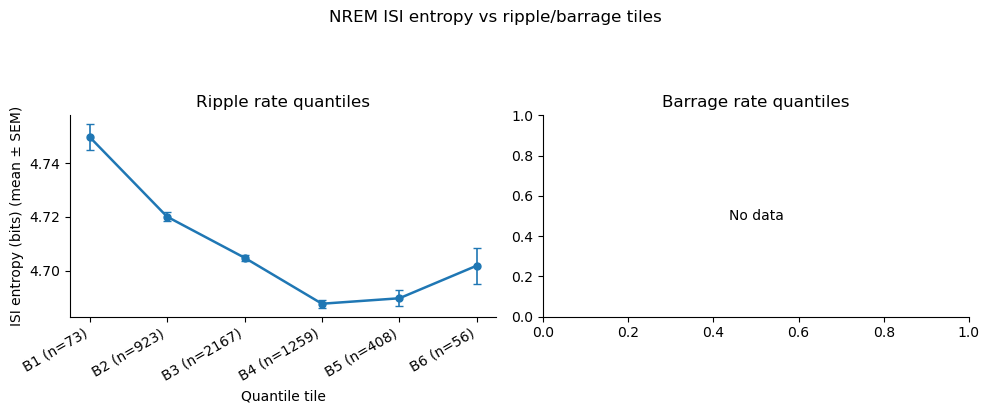

In [70]:
import pandas as pd
import numpy as np
import pathlib

def make_equal_width_tiles(series, k=6):
    """
    Creates exactly k equal-width tiles (B1..Bk) for the given series.
    The width is determined by (max - min) / k.
    """
    # 1. Setup Data and Categories
    v = pd.Series(series.to_numpy(float))
    ok = np.isfinite(v)
    
    # Define the exact categories B1...Bk
    out_cats = [f"B{i}" for i in range(1, k+1)]
    
    # Initialize output as Categorical with the known categories (allows empty bins)
    out = pd.Series(
        pd.Categorical([np.nan] * len(v), categories=out_cats, ordered=True),
        index=series.index
    )

    if ok.sum() == 0:
        return out

    vals = v[ok]
    min_val, max_val = vals.min(), vals.max()

    # 2. Case: Constant values (Min == Max)
    # pd.cut fails when range is 0. We force constant data into the middle bin.
    if min_val == max_val:
        mid_idx = int((k + 1) // 2)  # e.g., for k=6, puts data in B3
        target_label = f"B{mid_idx}"
        out.loc[vals.index] = target_label
        return out

    # 3. Main Logic: Equal Width Binning
    # pd.cut splits the range (min to max) into k equal linear intervals
    try:
        cut_vals = pd.cut(
            vals, 
            bins=k, 
            labels=out_cats, 
            include_lowest=True
        )
        out.loc[vals.index] = cut_vals
    except Exception as e:
        print(f"Binning failed: {e}")
        pass

    return out

def aggregate_tiles(df, by="ripple", value_col="isi_entropy", k=6):
    """
    Aggregate 'value_col' by k quantile tiles of 'ripple_rate' or 'barrage_rate'.
    Returns a tidy DataFrame with mean, SEM, and n per tile.
    """
    assert by in ("ripple", "barrage")
    rate_col = "ripple_rate" if by == "ripple" else "barrage_rate"
    tile_col = "tile_ripple" if by == "ripple" else "tile_barrage"

    dd = df.dropna(subset=[value_col, rate_col]).copy()
    if dd.empty:
        cats = [f"Q{i}" for i in range(1, k+1)]
        return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
                             f"{value_col}_mean": pd.Series([], dtype=float),
                             f"{value_col}_sem": pd.Series([], dtype=float),
                             "n": pd.Series([], dtype=int)})

    dd[tile_col] = make_equal_width_tiles(dd[rate_col], k=k)
    if dd[tile_col].isna().all():
        cats = [f"Q{i}" for i in range(1, k+1)]
        return pd.DataFrame({tile_col: pd.Categorical([], categories=cats, ordered=True),
                             f"{value_col}_mean": pd.Series([], dtype=float),
                             f"{value_col}_sem": pd.Series([], dtype=float),
                             "n": pd.Series([], dtype=int)})

    g = dd.groupby(tile_col, observed=False)
    res = g.agg(**{
        f"{value_col}_mean": (value_col, "mean"),
        f"{value_col}_sem":  (value_col, lambda x: x.std(ddof=1) / np.sqrt(max(1, x.count()))),
        "n":                 (value_col, "count")
    }).reset_index()

    cats = dd[tile_col].cat.categories
    res[tile_col] = pd.Categorical(res[tile_col], categories=cats, ordered=True)
    res = res.set_index(tile_col).reindex(cats).reset_index()
    res['n'] = res['n'].fillna(0).astype(int)
    return res

def _style(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
                    suptitle="ISI entropy vs ripple/barrage rate tiles"):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
    y_label = "ISI entropy (bits)"

    panels = [
        (axes[0], tiles_ripple, "tile_ripple",  "Ripple rate quantiles"),
        (axes[1], tiles_barrage,"tile_barrage", "Barrage rate quantiles")
    ]
    for ax, tiles, lab, title in panels:
        if tiles is None or tiles.empty or (lab not in tiles.columns) or (f"{value_col}_mean" not in tiles.columns):
            ax.text(0.5, 0.5, "No data", ha="center", va="center"); _style(ax); ax.set_title(title); continue
        tp = tiles.dropna(subset=[f"{value_col}_mean"]).copy()
        if tp.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center"); _style(ax); ax.set_title(title); continue

        x = np.arange(len(tp))
        y = tp[f"{value_col}_mean"].to_numpy(float)
        yerr = tp[f"{value_col}_sem"].fillna(0).to_numpy(float)
        ax.errorbar(x, y, yerr=yerr, fmt="-o", lw=1.8, ms=5, capsize=3, elinewidth=1.2)
        xt = [f"{lvl} (n={int(n)})" for lvl, n in zip(tp[lab].astype(str), tp["n"].to_numpy())]
        ax.set_xticks(x); ax.set_xticklabels(xt, rotation=30, ha='right')
        ax.set_xlabel("Quantile tile"); ax.set_ylabel(y_label + " (mean ± SEM)")
        ax.set_title(title); _style(ax)

    fig.suptitle(suptitle, y=1.05); fig.tight_layout(rect=[0, 0.03, 1, 0.95])
    return fig
# Make 6-quantile tiles by ripple/barrage rate and plot
tiles_rip = aggregate_tiles(out_df, by="ripple",  value_col="isi_entropy", k=6)
tiles_rip = tiles_rip.reset_index().rename(columns={'index': 'tile_ripple'})


fig = plot_tiles_line(tiles_rip, None, value_col="isi_entropy",
                      suptitle="NREM ISI entropy vs ripple/barrage tiles")
save_path = os.path.join(r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\ripple_ablate", f"{animal_name}_{day}_d2_tiles.png")
plt.savefig(save_path)
plt.show()

In [71]:
import pickle
save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\ripple_ablate"  # <-- your target folder
os.makedirs(save_dir, exist_ok=True)

import pickle
save_path = os.path.join(save_dir, f"{animal_name}_{day}_{brain_region}.pkl")
out_df = out_df.copy()
out_df["animal_name"]  = animal_name
out_df["day"]          = day
out_df["brain_region"] = brain_region

with open(save_path, "wb") as f:
    pickle.dump(out_df, f, protocol=pickle.HIGHEST_PROTOCOL)

